In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv('https://raw.githubusercontent.com/AhmadaliyevB/DAtalar/refs/heads/main/housing_LR.csv',index_col=0)
print("Ma’lumotlar o‘lchami:", df.shape)
display(df.head())
print("\\nUstunlar haqida ma’lumot:")
df.info()
print("\\nBo‘sh qiymatlar soni:")
print(df.isnull().sum())

Ma’lumotlar o‘lchami: (7278, 6)


,district,rooms,size,level,max_levels,price
0,Юнусабадский,3,57.0,4,4,52000.0
1,Яккасарайский,2,52.0,4,5,56000.0
2,Чиланзарский,2,42.0,4,4,37000.0
3,Чиланзарский,3,65.0,1,4,49500.0
4,Чиланзарский,3,70.0,3,5,55000.0


\nUstunlar haqida ma’lumot:
<class 'pandas.DataFrame'>
Index: 7278 entries, 0 to 7464
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   district    7278 non-null   str    
 1   rooms       7278 non-null   int64  
 2   size        7278 non-null   float64
 3   level       7278 non-null   int64  
 4   max_levels  7278 non-null   int64  
 5   price       7278 non-null   float64
dtypes: float64(2), int64(3), str(1)
memory usage: 398.0 KB
\nBo‘sh qiymatlar soni:
district      0
rooms         0
size          0
level         0
max_levels    0
price         0
dtype: int64


In [2]:
housing = df[df['district'] == 'Чиланзарский'].copy()
housing = housing[['size', 'price']].dropna()
X = housing[['size']]
y = housing['price']
print("Tanlangan ma’lumotlar soni:", len(housing))
display(housing.head())

Tanlangan ma’lumotlar soni: 1616


,size,price
2,42.0,37000.0
3,65.0,49500.0
4,70.0,55000.0
5,28.0,25500.0
6,30.0,21200.0


In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("O‘rgatish uchun:", X_train.shape[0])
print("Tekshirish uchun:", X_test.shape[0])

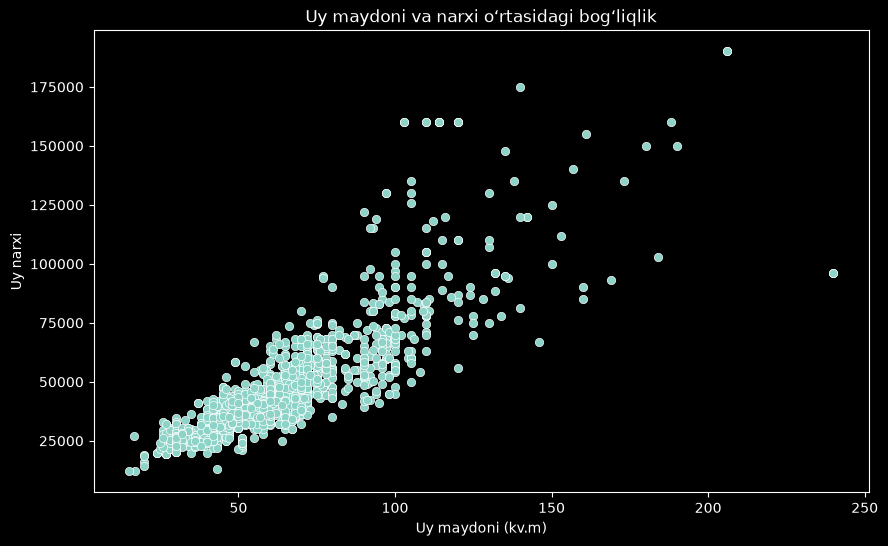

In [3]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=housing, x='size', y='price')
plt.title("Uy maydoni va narxi o‘rtasidagi bog‘liqlik")
plt.xlabel("Uy maydoni (kv.m)")
plt.ylabel("Uy narxi")
plt.show()

In [5]:
from sklearn.model_selection import train_test_split
X = df[['size']]
y = df['price']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [6]:
from sklearn.linear_model import LinearRegression
LR_model = LinearRegression()
LR_model.fit(X_train, y_train)
theta1 = LR_model.coef_[0]
theta0 = LR_model.intercept_
print("theta1 =", theta1)
print("theta0 =", theta0)

theta1 = 797.7600812318601
theta0 = -2010.5609497361802


In [7]:
y_pred = LR_model.predict(X_test)
natija = pd.DataFrame({'Haqiqiy narx': y_test.to_numpy(),'Bashorat qilingan narx': y_pred})
display(natija.head(10))

,Haqiqiy narx,Bashorat qilingan narx
0,39000.0,39472.963274
1,66000.0,76169.927011
2,25000.0,31495.362462
3,102000.0,45855.043924
4,30500.0,28304.322137
5,63000.0,55428.164899
6,31500.0,37079.683031
7,23000.0,36281.922949
8,77000.0,64203.525793
9,33000.0,37877.443112


In [8]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import numpy as np
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mse)
print(f"R² score: {r2:.4f}")
print(f"MSE: {mse:.2f}")
print(f"MAE: {mae:.2f}")
print(f"RMSE: {rmse:.2f}")

R² score: 0.6329
MSE: 330697424.31
MAE: 12314.31
RMSE: 18185.09


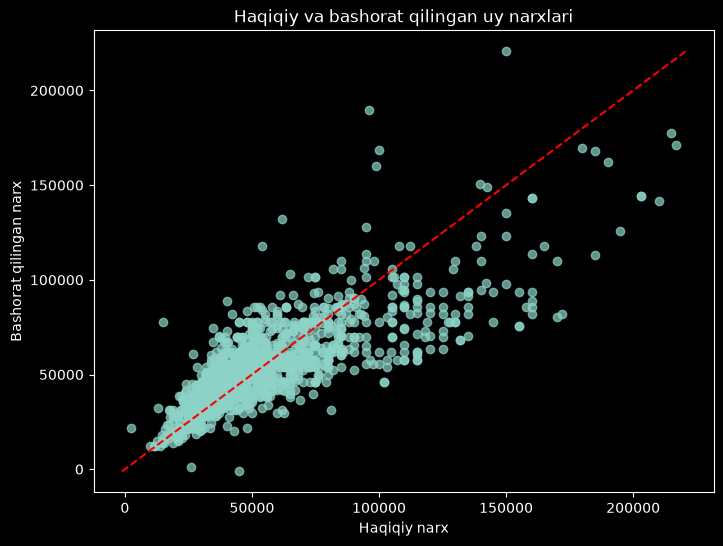

In [9]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.7)
min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())
plt.plot([min_value, max_value], [min_value, max_value], 'r--')
plt.xlabel("Haqiqiy narx")
plt.ylabel("Bashorat qilingan narx")
plt.title("Haqiqiy va bashorat qilingan uy narxlari")
plt.show()

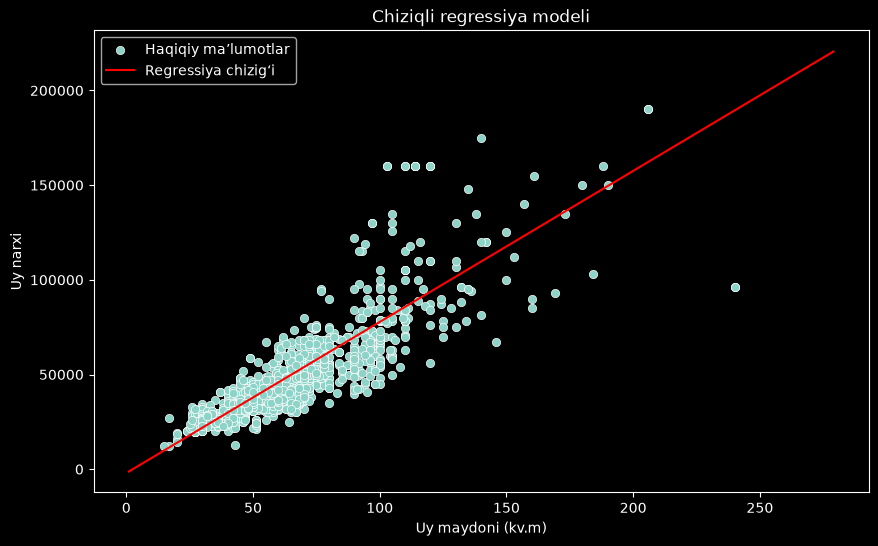

In [10]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=housing, x='size', y='price', label='Haqiqiy ma’lumotlar')
x_line = np.linspace(X['size'].min(), X['size'].max(), 100)
y_line = LR_model.predict(pd.DataFrame({'size': x_line}))
plt.plot(x_line, y_line, color='red', label='Regressiya chizig‘i')
plt.xlabel("Uy maydoni (kv.m)")
plt.ylabel("Uy narxi")
plt.title("Chiziqli regressiya modeli")
plt.legend()
plt.show()

In [11]:
from sklearn.preprocessing import StandardScaler
# Qiymatlarni standartlashtirish
scaler_X = StandardScaler()
scaler_y = StandardScaler()
X_train_scaled = scaler_X.fit_transform(X_train)
y_train_scaled = scaler_y.fit_transform(y_train.to_numpy().reshape(-1, 1)).ravel()
# Boshlang‘ich parametrlar
m = len(X_train_scaled)
w = 0.0
b = 0.0
learning_rate = 0.01
epochs = 1000
cost_history = []
for epoch in range(epochs):
    y_hat = w * X_train_scaled.ravel() + b
    errors = y_hat - y_train_scaled
    dw = (2 / m) * np.sum(errors * X_train_scaled.ravel())
    db = (2 / m) * np.sum(errors)
    w = w - learning_rate * dw
    b = b - learning_rate * db
    cost = np.mean((y_hat - y_train_scaled) ** 2)
    cost_history.append(cost)
print("Gradiyent pastlash yakunlandi.")
print("Oxirgi MSE (standartlashtirilgan qiymatlarda):", round(cost_history[-1], 6))
print("Yakuniy w:", round(w, 4))
print("Yakuniy b:", round(b, 4))

Gradiyent pastlash yakunlandi.
Oxirgi MSE (standartlashtirilgan qiymatlarda): 0.368721
Yakuniy w: 0.7945
Yakuniy b: -0.0


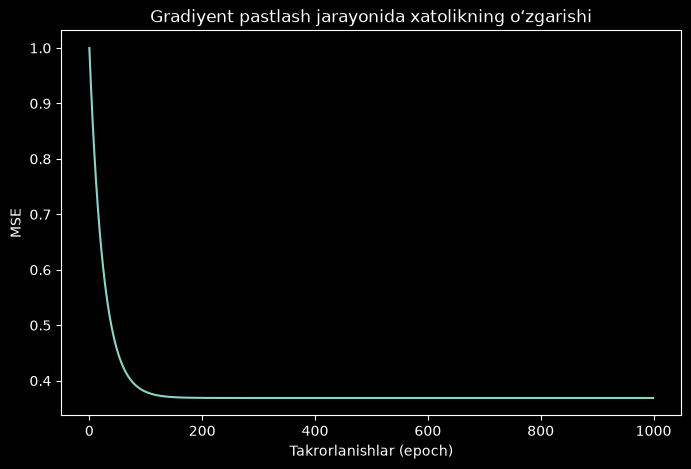

In [12]:
plt.figure(figsize=(8, 5))
plt.plot(cost_history)
plt.xlabel("Takrorlanishlar (epoch)")
plt.ylabel("MSE")
plt.title("Gradiyent pastlash jarayonida xatolikning o‘zgarishi")
plt.show()


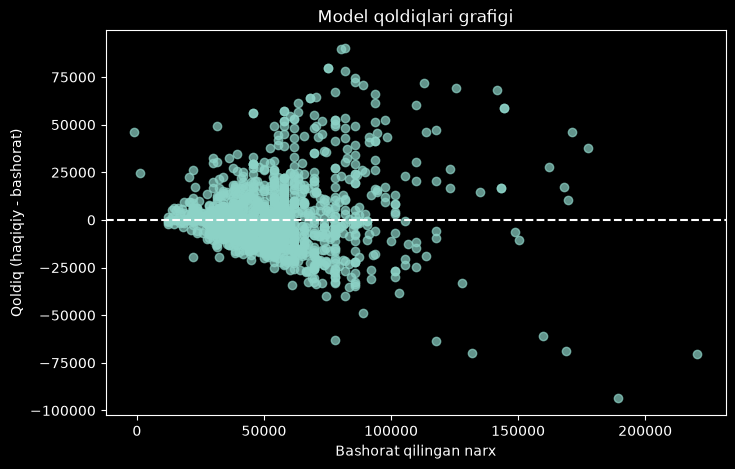

In [13]:
residuals = y_test.to_numpy() - y_pred
plt.figure(figsize=(8, 5))
plt.scatter(y_pred, residuals, alpha=0.7)
plt.axhline(y=0, linestyle="--")
plt.xlabel("Bashorat qilingan narx")
plt.ylabel("Qoldiq (haqiqiy - bashorat)")
plt.title("Model qoldiqlari grafigi")
plt.show()

In [14]:
print(f"Model tenglamasi: price = {theta0:.2f} + ({theta1:.2f} * size)")
if theta1 > 0:
    print("Talqin: maydon oshishi bilan model bashorat qilgan narx ham oshadi.")
elif theta1 < 0:
    print("Talqin: maydon oshishi bilan model bashorat qilgan narx kamayadi.")
else:
    print("Talqin: ushbu modelda maydon koeffitsiyenti nolga teng.")

Model tenglamasi: price = -2010.56 + (797.76 * size)
Talqin: maydon oshishi bilan model bashorat qilgan narx ham oshadi.


In [15]:
new_size = 70  # Uy maydoni, kv.m
new_house = pd.DataFrame({"size": [new_size]})
predicted_price = LR_model.predict(new_house)[0]
print(f"{new_size} kv.m uy uchun bashorat qilingan narx: {predicted_price:.2f}")

70 kv.m uy uchun bashorat qilingan narx: 53832.64
